# PathSnap: Exploratory data analysis (Member A)

Partitions used: **train** (80 trips) and **student_test** (10 trips). Evaluator-testing data is not used anywhere.
Every table and figure below says which partition it covers.

**How to use this notebook**
1. Put the data in `data/train/<id>/` and `data/student_test/<id>/` (not committed to git).
2. From the repo root run `python -m src.data.eda --root data --out results/eda` (tables) and
   `python -m src.data.eda_plots --root data --out results/eda` (figures and extra tables).
3. Open this notebook and run all cells. It only reads the files those two scripts write.

Checklist from the work order: inventory, missing or invalid GPS, timestamps and gaps, extent, network size and connectivity,
route validity, GPS-to-reference distance, anomalous trips, and the data-quality log.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent                      # notebook lives in notebooks/
sys.path.insert(0, str(ROOT))
EDA = ROOT / "results" / "eda"
FIG = EDA / "figures"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

inv = pd.read_csv(EDA / "inventory.csv", dtype={"trip_id": str})
miss = pd.read_csv(EDA / "missing_values.csv", dtype={"trip_id": str})
far = pd.read_csv(EDA / "far_points_by_trip.csv", dtype={"trip_id": str})

import io
from PIL import Image as PILImage

def show_file(p, max_w=1300):
    # display a PNG, downscaled so the saved notebook stays small
    im = PILImage.open(p).convert("RGB")
    if im.width > max_w:
        im = im.resize((max_w, int(im.height * max_w / im.width)))
    buf = io.BytesIO(); im.save(buf, format="PNG", optimize=True)
    display(Image(data=buf.getvalue()))

def show(name):
    p = FIG / name
    show_file(p) if p.exists() else print("missing figure:", p)

print("repo root:", ROOT)

repo root: /tmp/claude-0/-home-claude/1be7279c-2d08-5775-bc36-882162f53459/scratchpad/work/repo


## 1. Dataset inventory (partitions: train and student_test)
One row per trip is in `results/eda/inventory.csv`. Each trip has four files: `.track` (GPS rows), `.nodes` (row = node id),
`.arcs` (row = arc id, columns from and to node) and `.route` (ordered reference arc ids).

In [2]:
print(inv.groupby("partition").size().rename("trips").to_frame())
cols = ["n_gps", "n_nodes", "n_arcs", "route_len", "file_kb"]
display(inv.groupby("partition")[cols].agg(["min", "median", "max"]).round(0).T)
print("files per trip: 4 (.track, .nodes, .arcs, .route)")

              trips
partition          
student_test     10
train            80


partition         student_test     train
n_gps     min            262.0     361.0
          median        1420.0    1529.0
          max           3958.0   19313.0
n_nodes   min           1770.0     299.0
          median        6596.0    9608.0
          max          26635.0  155003.0
n_arcs    min           3577.0     649.0
          median       13145.0   19526.0
          max          56027.0  307392.0
route_len min             95.0      59.0
          median         250.0     280.0
          max           1323.0    2266.0
file_kb   min             73.0      53.0
          median         296.0     484.0
          max           1179.0    6727.0

files per trip: 4 (.track, .nodes, .arcs, .route)


## 2. Missing or invalid GPS rows, duplicate timestamps (partitions: train and student_test)

In [3]:
tot = miss[["n_rows_raw", "nan_rows", "out_of_range_rows", "rows_dropped", "duplicate_timestamps", "time_goes_backwards"]].sum()
display(miss.groupby("partition")[["n_rows_raw", "nan_rows", "out_of_range_rows", "rows_dropped", "duplicate_timestamps", "time_goes_backwards"]].sum())
print("All 90 trips: %d NaN rows, %d out-of-range rows, %d duplicate timestamps, %d timestamps going backwards."
      % (tot.nan_rows, tot.out_of_range_rows, tot.duplicate_timestamps, tot.time_goes_backwards))

,n_rows_raw,nan_rows,out_of_range_rows,rows_dropped,duplicate_timestamps,time_goes_backwards
partition,,,,,,
student_test,19160,0,0,0,0,0
train,208417,0,0,0,0,0


All 90 trips: 0 NaN rows, 0 out-of-range rows, 0 duplicate timestamps, 0 timestamps going backwards.


## 3. Timestamp ordering and gaps (partitions: train and student_test)
Most steps are exactly 1 s, but a few trips have long pauses. Models must use the real time difference and treat very large gaps as breaks.

Share of time steps equal to 1 s (per trip):


,count,mean,std,min,25%,50%,75%,max
partition,,,,,,,,
student_test,10.0,0.982,0.043,0.861,0.987,0.999,1.0,1.0
train,80.0,0.938,0.117,0.531,0.959,0.991,1.0,1.0


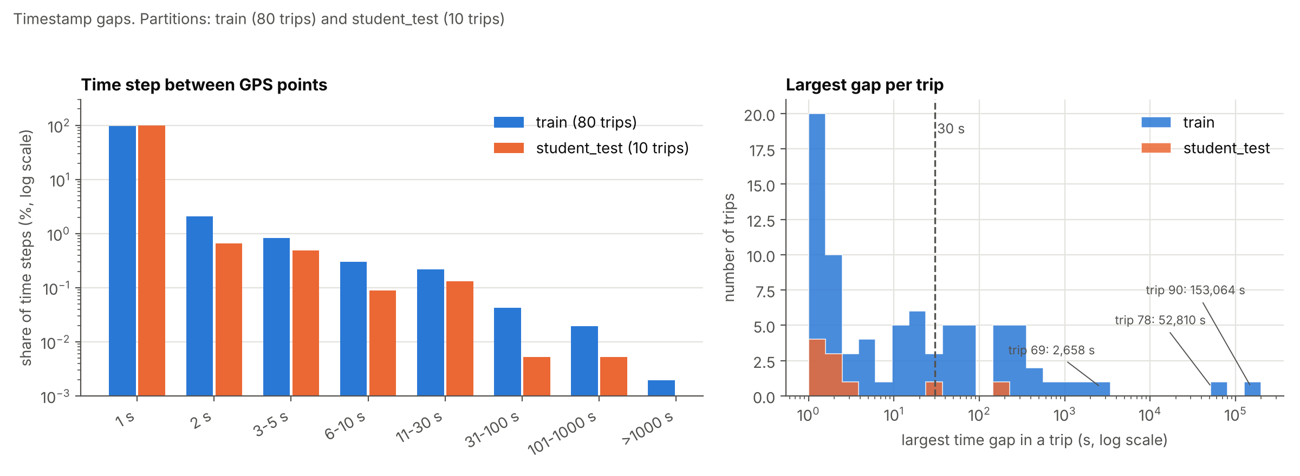

Trips with a gap longer than 30 s: 30 of 90


,partition,trip_id,n_gaps_gt10s,n_gaps_gt30s,max_gap_s,share_dt_equal_1s
0,train,00000090,6,1,153064.0,0.5813
1,train,00000078,25,2,52810.0,0.7552
2,train,00000069,2,2,2658.0,0.9894
3,train,00000021,2,2,2161.0,0.9996
4,train,00000011,1,1,909.0,0.9996
5,train,00000042,37,22,670.0,0.9895
6,train,00000081,86,37,536.0,0.7198
7,train,00000024,2,2,458.0,0.9712
8,train,00000044,2,2,341.0,0.9009
9,train,00000084,4,4,312.0,0.9969


In [4]:
print("Share of time steps equal to 1 s (per trip):")
display(miss.groupby("partition").share_dt_equal_1s.describe().round(3))
show("gap_histogram.png")
gaps = pd.read_csv(EDA / "trips_with_gap_gt30s.csv", dtype={"trip_id": str})
print("Trips with a gap longer than 30 s:", len(gaps), "of", len(miss))
display(gaps[["partition", "trip_id", "n_gaps_gt10s", "n_gaps_gt30s", "max_gap_s", "share_dt_equal_1s"]].head(12))

## 4. Geographic extent and trajectory length (partitions: train and student_test)

partition         student_test  train
extent_km min              4.3    1.4
          median           7.2    9.5
          max             48.3   78.4
track_km  min              5.5    6.3
          median          20.9   24.0
          max             71.6  168.9

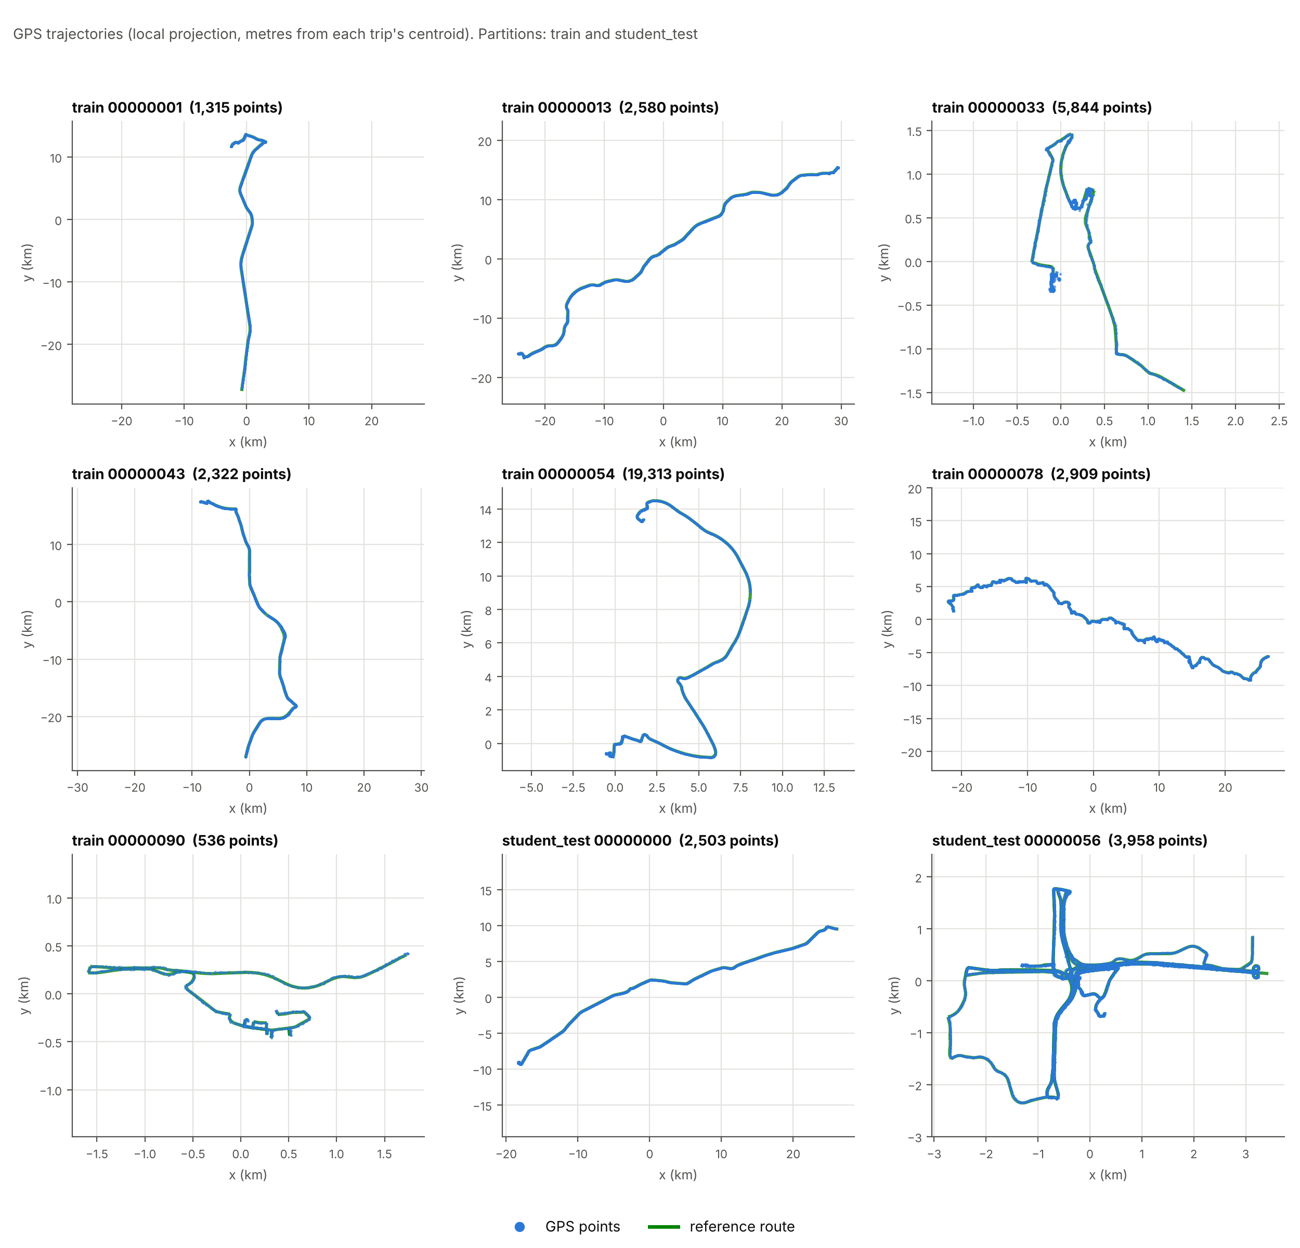

In [5]:
display(inv.groupby("partition")[["extent_km", "track_km"]].agg(["min", "median", "max"]).round(1).T)
show("trajectories.png")

## 5. Road-network size and connectivity (partitions: train and student_test)
Isolated nodes are nodes that no arc uses. Components are the separate connected pieces of the network
(`scipy.sparse.csgraph.connected_components`); a trip's route stays inside one piece, so many pieces are not an error.

partition                student_test       train
n_nodes          min         1770.000     299.000
                 median      6596.500    9608.000
                 max        26635.000  155003.000
n_arcs           min         3577.000     649.000
                 median     13145.000   19526.500
                 max        56027.000  307392.000
isolated_nodes   min            0.000       0.000
                 median         0.000       0.000
                 max            0.000       0.000
n_components     min            5.000       1.000
                 median        11.000      20.000
                 max          100.000     421.000
giant_comp_share min            0.874       0.693
                 median         0.971       0.981
                 max            0.991       1.000

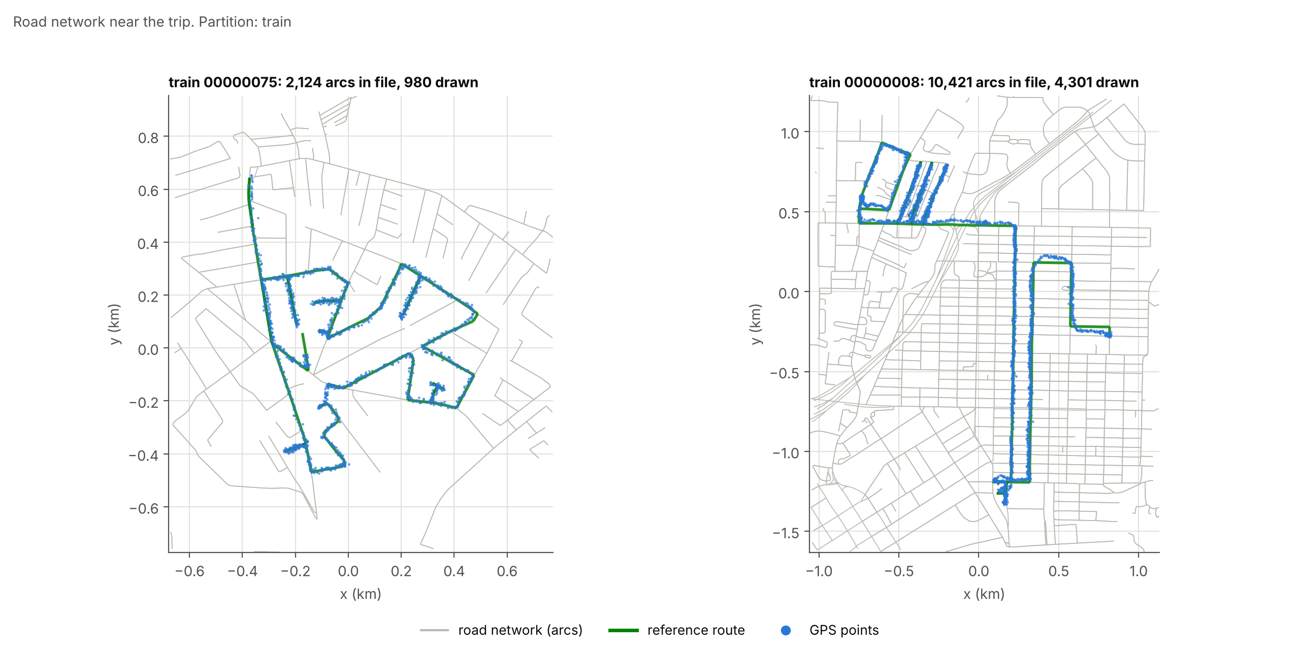

In [6]:
display(inv.groupby("partition")[["n_nodes", "n_arcs", "isolated_nodes", "n_components", "giant_comp_share"]].agg(["min", "median", "max"]).round(3).T)
show("road_network.png")

## 6. Reference-route validity (partitions: train and student_test)
Share of consecutive route arcs where the next arc starts where the previous one ends.

In [7]:
display(inv.groupby("partition").route_connected.describe().round(4))
print("Trips below 0.99:", inv.loc[inv.route_connected < 0.99, ["partition", "trip_id", "route_connected"]].to_dict("records"))

,count,mean,std,min,25%,50%,75%,max
partition,,,,,,,,
student_test,10.0,0.9997,0.0009,0.9973,1.0,1.0,1.0,1.0
train,80.0,0.9993,0.0025,0.9813,1.0,1.0,1.0,1.0


Trips below 0.99: [{'partition': 'train', 'trip_id': '00000075', 'route_connected': 0.9813}]


## 7. GPS-to-reference-arc distance (partitions: train and student_test)
Reference labels come from the monotone alignment in `src/data/labels.py`: the route index can stay or move forward, never backwards,
and the cost is the point-to-arc distance in metres. A good alignment gives a median of a few metres.

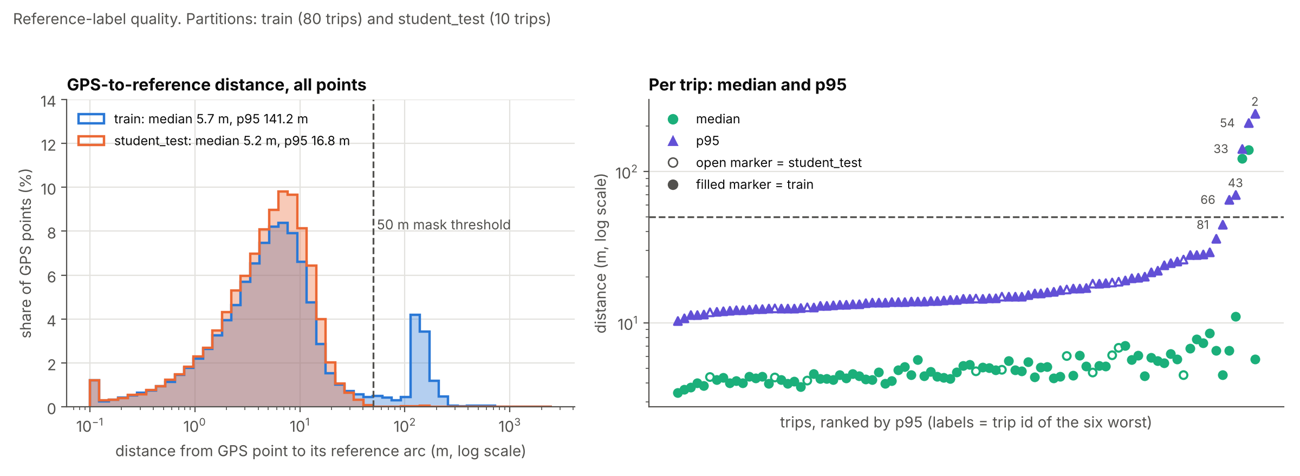

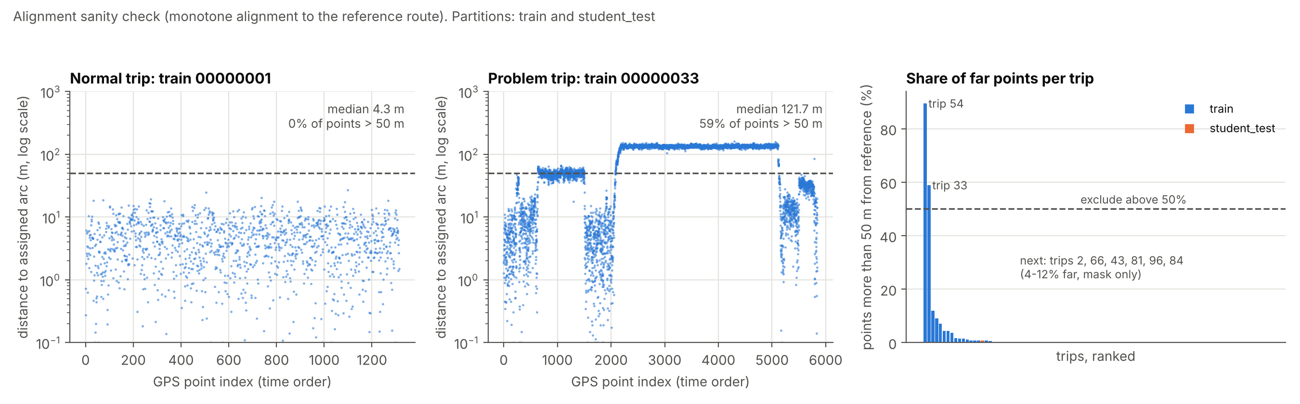

partition               student_test  train
gps_to_ref_med_m count          10.0   80.0
                 mean            5.1    8.1
                 std             0.9   19.8
                 min             4.2    3.4
                 25%             4.4    4.3
                 50%             4.7    4.6
                 75%             5.7    5.5
                 max             6.8  139.2
gps_to_ref_p95_m count          10.0   80.0
                 mean           16.4   24.3
                 std             4.3   36.7
                 min            11.7   10.3

In [8]:
show("gps_to_reference_distance.png")
show("alignment_check.png")
display(inv.groupby("partition")[["gps_to_ref_med_m", "gps_to_ref_p95_m", "gps_to_ref_p99_m"]].describe().round(1).T.head(12))

## 8. Anomalous trips and decisions
A GPS point is **far** if it is more than 50 m from its reference arc (the mask threshold, to be confirmed with B).
The table is sorted by the share of far points.

In [9]:
display(far.sort_values("share_gt_mask", ascending=False).head(10)[
    ["partition", "trip_id", "n_gps", "median_m", "p95_m", "p99_m", "share_gt_mask", "suggested_action"]])

,partition,trip_id,n_gps,median_m,p95_m,p99_m,share_gt_mask,suggested_action
44,train,00000054,19313,139.22,209.28,216.88,0.8943,exclude
26,train,00000033,5844,121.66,141.19,145.70,0.5886,exclude
1,train,00000002,7243,5.75,241.25,479.03,0.1198,mask far points
53,train,00000066,4325,6.57,65.16,635.83,0.0899,mask far points
35,train,00000043,2322,11.00,70.04,161.29,0.0711,mask far points
64,train,00000081,3224,4.53,44.53,137.20,0.0444,mask far points
76,train,00000096,3271,4.44,20.22,81.92,0.0443,mask far points
67,train,00000084,16031,6.55,36.09,76.70,0.0369,mask far points
14,train,00000019,2354,5.51,15.30,90.78,0.0166,keep
15,train,00000020,2353,5.43,23.99,77.35,0.0153,keep


| Trips | What the maps and numbers show | Decision |
|---|---|---|
| 33 and 54 (train) | Most points are far from the route: dense GPS blobs where the vehicle sat still and the GPS drifted. 59% and 89% of points are over 50 m away. The moving parts match the route. | Exclude from supervised training. Keep for diagnostic evaluation only. |
| 43, 66, 2, 81 (train) | Mostly good. 7%, 9%, 12% and 4% of points are over 50 m away (43 runs alongside the route with a small side offset). | Keep the trip. Mask points beyond the threshold instead of dropping the trip. |
| 90 and 78 (train) | Valid GPS but huge time gaps (153,064 s and 52,810 s). | Keep. Use real timestamps and treat large gaps as sequence breaks. |

The full log with evidence is in `results/eda/data_quality.md`. Folium maps are in `maps/`; screenshots are below.

map_normal_zoomed.png


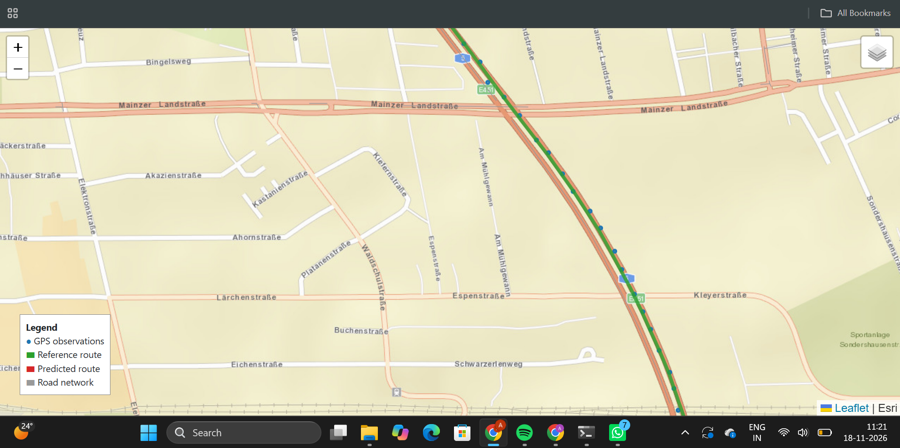

map_trip33_gps_blobs.png


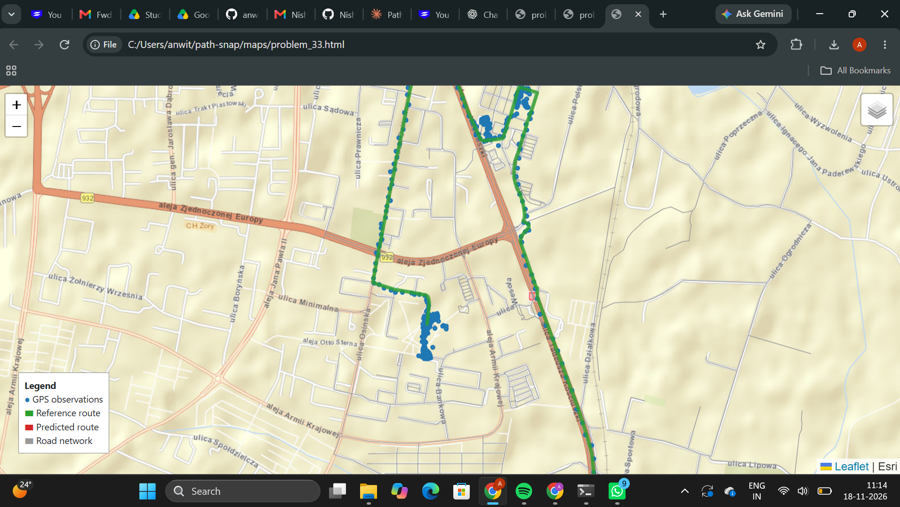

map_trip43_side_offset.png


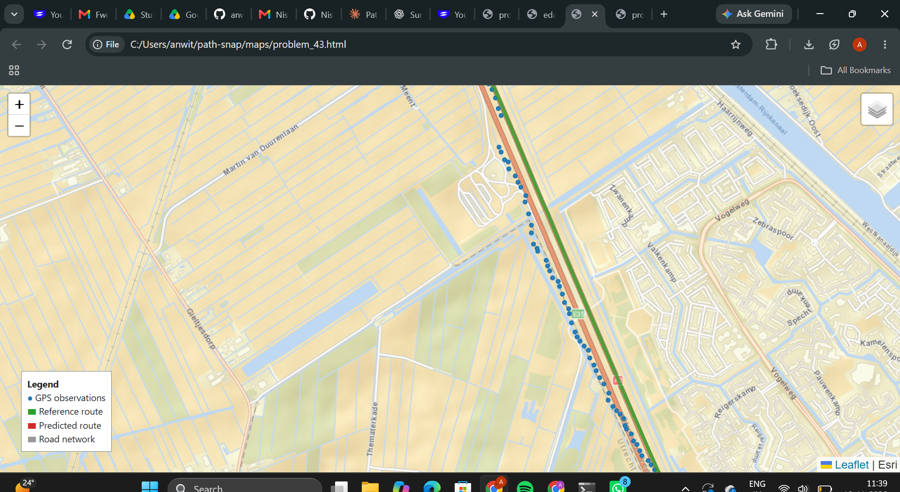

map_trip54_gps_blobs.png


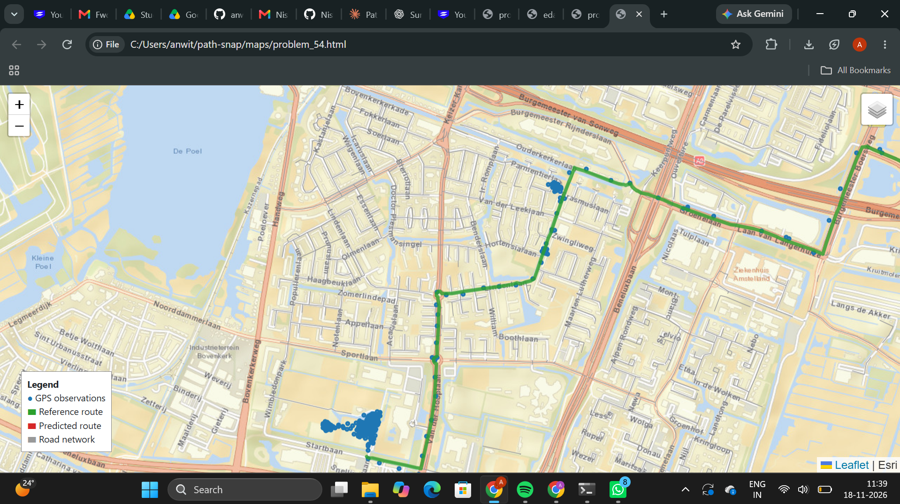

In [10]:
for f in ["map_normal_zoomed.png", "map_trip33_gps_blobs.png", "map_trip43_side_offset.png", "map_trip54_gps_blobs.png"]:
    p = ROOT / "report" / "figures" / f
    if p.exists():
        print(f); show_file(p, 900)

## 9. Data-quality log (summary)
Invalid or NaN GPS rows: none. Timestamps going backwards or duplicated: none. Isolated nodes: none.
Long gaps in 30 trips, up to 153,064 s. Reference labels are a good but imperfect label (route continuity at least 0.98 in every trip).
See `results/eda/data_quality.md` for the issue, evidence and decision of each item.